# 04 · Clientes, recompra e pagamentos

**Pergunta:** o cliente volta? Quem são os clientes mais valiosos, como eles pagam e o que influencia a recompra?

Base: pedidos válidos de jan/2017 a ago/2018. Cliente = `customer_unique_id`. Para não contar como recompra um carrinho dividido em vários pedidos no mesmo momento, **compra** = dia distinto em que o cliente comprou.

## Principais conclusões

- **O cliente quase não volta:** dos 94,7 mil clientes, só 2,2% compraram mais de uma vez, e os recorrentes geram 4,2% da receita. A retenção mensal fica abaixo de 0,5%.
- **A recompra é baixa em qualquer experiência.** Quem deu nota 4–5 volta um pouco mais do que quem deu 1–2 (diferença estatisticamente significativa), mas todas as faixas ficam perto de 2%. Isso indica um limite estrutural do modelo de marketplace: o cliente compra na vitrine do parceiro e não cria vínculo com a loja.
- **Valor concentrado em clientes de compra única:** "Alto valor em risco" (15% dos clientes) e "Novos de alto valor" (16%) somam 57% da receita e são o público natural de campanhas de reativação.
- **Pagamento:** o cartão de crédito responde por 78,5% do valor, e 80,5% desse valor é parcelado (média de 3,5 parcelas). O boleto tem 18%.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from olist import config, data, prep, viz
from olist.viz import CORES, brl, num, pct

viz.aplicar_estilo()
from statsmodels.stats.proportion import proportions_ztest

In [2]:
t = data.carregar_todas()
pedidos = prep.carregar_base_pedidos()
validos = pedidos[pedidos.valido].copy()
validos["dia"] = validos.order_purchase_timestamp.dt.normalize()

clientes = validos.groupby("customer_unique_id").agg(
    primeira=("order_purchase_timestamp", "min"),
    ultima=("order_purchase_timestamp", "max"),
    pedidos=("order_id", "nunique"),
    compras=("dia", "nunique"),
    gmv=("gmv", "sum"),
    uf=("customer_state", "first"),
)

## 1. Quantos clientes voltam

In [3]:
recorrentes = clientes.compras > 1
compras_por_dia = validos.drop_duplicates(["customer_unique_id", "dia"]).sort_values("dia")
compras_por_dia["ordem"] = compras_por_dia.groupby("customer_unique_id").cumcount()
segunda = compras_por_dia[compras_por_dia.ordem == 1].set_index("customer_unique_id").dia
intervalo = (segunda - clientes.loc[segunda.index, "primeira"].dt.normalize()).dt.days

pd.Series({
    "Clientes únicos": num(len(clientes)),
    "Clientes com 2+ compras": f"{num(recorrentes.sum())} ({pct(recorrentes.mean())})",
    "Receita vinda de clientes recorrentes": pct(clientes.loc[recorrentes, "gmv"].sum() / clientes.gmv.sum()),
    "Dias até a 2ª compra (mediana)": num(intervalo.median()),
    "2ª compra em até 90 dias": pct((intervalo <= 90).mean()),
}).to_frame("valor")

,valor
Clientes únicos,94.703
Clientes com 2+ compras,"2.053 (2,2%)"
Receita vinda de clientes recorrentes,"4,2%"
Dias até a 2ª compra (mediana),74
2ª compra em até 90 dias,"55,0%"


In [4]:
distribuicao = clientes.compras.clip(upper=4).value_counts().sort_index()
distribuicao.index = ["1 compra", "2 compras", "3 compras", "4 ou mais"]
distribuicao.to_frame("clientes").assign(**{"%": (distribuicao / distribuicao.sum()).map(lambda v: pct(v, 2))})

,clientes,%
1 compra,92650,"97,83%"
2 compras,1898,"2,00%"
3 compras,123,"0,13%"
4 ou mais,32,"0,03%"


## 2. Retenção por coorte

Cada linha é a turma de clientes que fez a primeira compra naquele mês; cada coluna mostra a % dessa turma que comprou de novo N meses depois.

Retenção média: 1 mês depois 0,48% | 3 meses 0,26% | 6 meses 0,26%


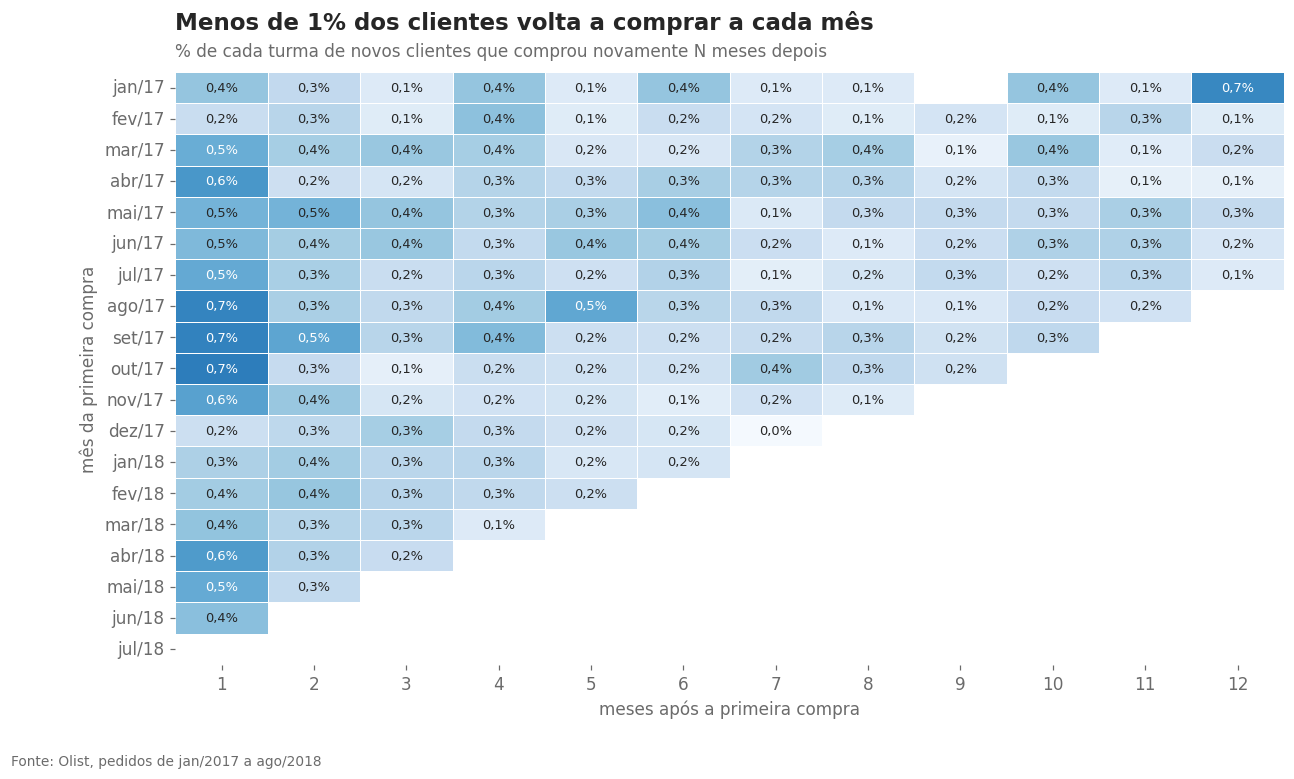

In [5]:
def mes_indice(datas):
    return datas.dt.year * 12 + datas.dt.month

primeira = validos.customer_unique_id.map(clientes.primeira)
validos["coorte"] = primeira.dt.to_period("M").dt.to_timestamp()
validos["meses_desde"] = mes_indice(validos.order_purchase_timestamp) - mes_indice(primeira)

fim = pd.Timestamp(config.FIM_MES_COMPLETO)
ativos = validos[validos.coorte <= fim].groupby(["coorte", "meses_desde"]).customer_unique_id.nunique().unstack()
retencao = ativos.div(ativos[0], axis=0).loc[:, 1:12]
# Esconde meses que ainda não tinham acontecido no fim da série (jul/2018)
limite = (mes_indice(pd.Series(fim)) .iloc[0] - mes_indice(pd.Series(retencao.index))).values
for i, coorte in enumerate(retencao.index):
    retencao.loc[coorte, retencao.columns > limite[i]] = np.nan

media_m1, media_m3, media_m6 = (retencao[m].mean() for m in (1, 3, 6))
print(f"Retenção média: 1 mês depois {pct(media_m1, 2)} | 3 meses {pct(media_m3, 2)} | 6 meses {pct(media_m6, 2)}")

fig, ax = plt.subplots(figsize=(13, 7))
sns.heatmap(retencao, annot=retencao.map(lambda v: "" if pd.isna(v) else pct(v, 1)), fmt="", cmap="Blues",
            vmin=0, vmax=0.01, cbar=False, ax=ax, linewidths=0.5, linecolor="white", annot_kws={"fontsize": 8.5})
ax.set_yticklabels([viz.mes_ano(pd.Timestamp(d)) for d in retencao.index], rotation=0)
ax.set_xlabel("meses após a primeira compra")
ax.set_ylabel("mês da primeira compra")
ax.grid(False)
viz.titulo(ax, "Menos de 1% dos clientes volta a comprar a cada mês", "% de cada turma de novos clientes que comprou novamente N meses depois")
viz.fonte(fig)
viz.salvar(fig, "04_coortes")

## 3. A primeira experiência influencia a volta?

Clientes com primeira compra até 180 dias antes do fim da série, para que todos tenham a mesma janela de observação. Medimos a % que comprou novamente em até 180 dias.

In [6]:
corte = pd.Timestamp(config.FIM_SERIE_DIARIA) - pd.Timedelta(days=180)
primeiro = validos.sort_values("order_purchase_timestamp").drop_duplicates("customer_unique_id")
primeiro = primeiro[primeiro.order_purchase_timestamp <= corte].copy()
primeiro["recompra_180"] = (primeiro.customer_unique_id.map(segunda) - primeiro.dia).dt.days.le(180)

por_nota = primeiro.groupby("review_score").recompra_180.agg(taxa="mean", clientes="size")
por_atraso = primeiro.groupby("atrasado").recompra_180.agg(taxa="mean", clientes="size").rename(index={0.0: "no prazo", 1.0: "com atraso"})
print(f"Clientes observados: {num(len(primeiro))} | recompra em 180 dias: {pct(primeiro.recompra_180.mean(), 2)}")
print()
print(por_atraso.assign(taxa=por_atraso.taxa.map(lambda v: pct(v, 2))).to_string())
print()
print(por_nota.assign(taxa=por_nota.taxa.map(lambda v: pct(v, 2))).to_string())

def teste(grupo_a, grupo_b):
    sucessos = [grupo_a.sum(), grupo_b.sum()]
    totais = [len(grupo_a), len(grupo_b)]
    return proportions_ztest(sucessos, totais)[1]

p_atraso = teste(primeiro.loc[primeiro.atrasado == 0, "recompra_180"], primeiro.loc[primeiro.atrasado == 1, "recompra_180"])
p_nota = teste(primeiro.loc[primeiro.review_score >= 4, "recompra_180"], primeiro.loc[primeiro.review_score <= 2, "recompra_180"])
print(f"\np-valor (no prazo vs atraso): {p_atraso:.3f} | p-valor (nota 4–5 vs 1–2): {p_nota:.3f}")

Clientes observados: 54.580 | recompra em 180 dias: 2,00%

             taxa  clientes
atrasado                   
no prazo    2,03%     50232
com atraso  1,62%      3271

               taxa  clientes
review_score                 
1.00          1,70%      5771
2.00          1,48%      1756
3.00          1,94%      4701
4.00          1,84%     10795
5.00          2,15%     31113

p-valor (no prazo vs atraso): 0.108 | p-valor (nota 4–5 vs 1–2): 0.016


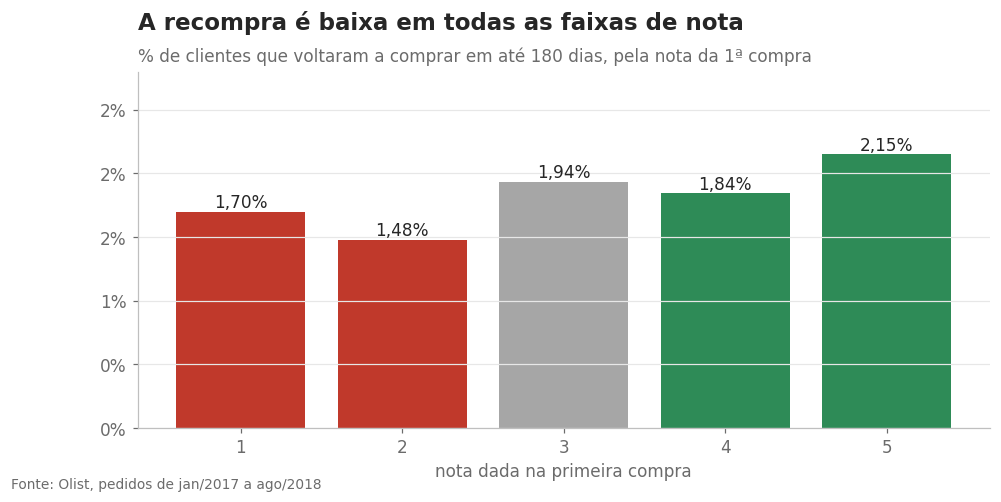

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.2))
cores = [CORES["negativo"], CORES["negativo"], CORES["neutro"], CORES["positivo"], CORES["positivo"]]
barras = ax.bar(por_nota.index.astype(int).astype(str), por_nota.taxa, color=cores)
for barra, v in zip(barras, por_nota.taxa):
    ax.text(barra.get_x() + barra.get_width() / 2, v, pct(v, 2), ha="center", va="bottom")
ax.yaxis.set_major_formatter(viz.eixo_pct)
ax.set_xlabel("nota dada na primeira compra")
ax.set_ylim(0, por_nota.taxa.max() * 1.3)
viz.titulo(ax, "A recompra é baixa em todas as faixas de nota", "% de clientes que voltaram a comprar em até 180 dias, pela nota da 1ª compra")
viz.fonte(fig)
viz.salvar(fig, "04_recompra_por_nota")

## 4. Segmentação RFM

**R**ecência (dias desde a última compra), **F**requência (número de compras) e **M**onetário (receita total). R e M são divididos em quintis (1 = pior, 5 = melhor). Como quase todos compraram uma única vez, a frequência separa só o grupo dos recorrentes.

In [8]:
referencia = pd.Timestamp(config.FIM_JANELA) + pd.Timedelta(days=1)
rfm = pd.DataFrame({
    "recencia": (referencia - clientes.ultima).dt.days,
    "frequencia": clientes.compras,
    "valor": clientes.gmv,
})
rfm["R"] = pd.qcut(rfm.recencia, 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["M"] = pd.qcut(rfm.valor.rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["segmento"] = np.select(
    [rfm.frequencia >= 2, (rfm.R >= 4) & (rfm.M >= 4), rfm.R >= 4, (rfm.R <= 2) & (rfm.M >= 4), rfm.R <= 2],
    ["Recorrentes", "Novos de alto valor", "Novos", "Alto valor em risco", "Adormecidos"],
    default="Intermediários",
)
ordem_segmentos = ["Recorrentes", "Novos de alto valor", "Novos", "Intermediários", "Alto valor em risco", "Adormecidos"]
segmentos = rfm.groupby("segmento").agg(clientes=("valor", "size"), receita=("valor", "sum"), ticket=("valor", "mean"),
                                        recencia=("recencia", "mean")).reindex(ordem_segmentos)
segmentos["% clientes"] = segmentos.clientes / segmentos.clientes.sum()
segmentos["% receita"] = segmentos.receita / segmentos.receita.sum()
segmentos.assign(
    receita=segmentos.receita.map(brl), ticket=segmentos.ticket.map(brl), recencia=segmentos.recencia.round(0),
    **{"% clientes": segmentos["% clientes"].map(pct), "% receita": segmentos["% receita"].map(pct)},
)

,clientes,receita,ticket,recencia,% clientes,% receita
segmento,,,,,,
Recorrentes,2053,R$ 660 mil,R$ 321,193.00,"2,2%","4,2%"
Novos de alto valor,14800,"R$ 4,5 mi",R$ 303,94.00,"15,6%","28,6%"
Novos,22196,"R$ 1,6 mi",R$ 73,92.00,"23,4%","10,3%"
Intermediários,18618,"R$ 2,9 mi",R$ 154,223.00,"19,7%","18,2%"
Alto valor em risco,14159,"R$ 4,4 mi",R$ 310,395.00,"15,0%","28,0%"
Adormecidos,22877,"R$ 1,7 mi",R$ 73,397.00,"24,2%","10,6%"


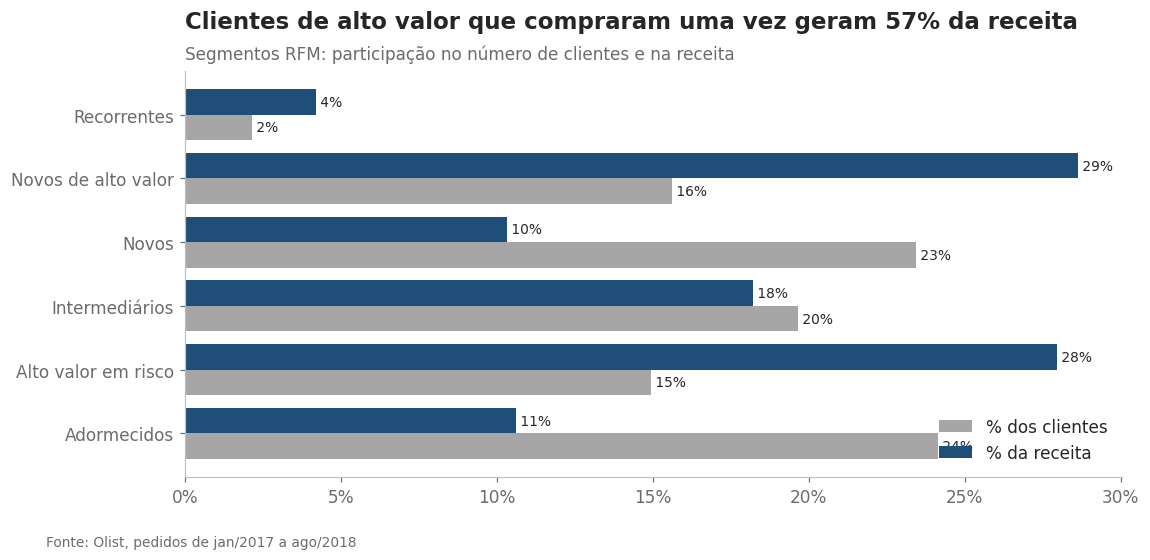

In [9]:
fig, ax = plt.subplots(figsize=(11, 4.8))
y = np.arange(len(segmentos))
ax.barh(y + 0.2, segmentos["% clientes"], height=0.4, color=CORES["neutro"], label="% dos clientes")
ax.barh(y - 0.2, segmentos["% receita"], height=0.4, color=CORES["principal"], label="% da receita")
for yi, (c, r) in enumerate(zip(segmentos["% clientes"], segmentos["% receita"])):
    ax.text(c, yi + 0.2, f" {pct(c, 0)}", va="center", fontsize=9)
    ax.text(r, yi - 0.2, f" {pct(r, 0)}", va="center", fontsize=9)
ax.set_yticks(y, segmentos.index)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(viz.eixo_pct)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
alto_valor = segmentos.loc[["Novos de alto valor", "Alto valor em risco"], "% receita"].sum()
viz.titulo(ax, f"Clientes de alto valor que compraram uma vez geram {pct(alto_valor, 0)} da receita",
           "Segmentos RFM: participação no número de clientes e na receita")
viz.fonte(fig)
viz.salvar(fig, "04_rfm")

## 5. Meios de pagamento e parcelamento

In [10]:
pag = t["payments"][t["payments"].order_id.isin(validos.order_id)]
nomes = {"credit_card": "Cartão de crédito", "boleto": "Boleto", "voucher": "Voucher", "debit_card": "Cartão de débito", "not_defined": "Não definido"}
por_tipo = pag.groupby("payment_type").agg(pedidos=("order_id", "nunique"), valor=("payment_value", "sum")).rename(index=nomes)
por_tipo = por_tipo.sort_values("valor", ascending=False)
por_tipo["% do valor"] = por_tipo.valor / por_tipo.valor.sum()
por_tipo.assign(valor=por_tipo.valor.map(brl), **{"% do valor": por_tipo["% do valor"].map(pct)})

,pedidos,valor,% do valor
payment_type,,,
Cartão de crédito,75387,"R$ 12,3 mi","78,5%"
Boleto,19477,"R$ 2,8 mi","18,0%"
Voucher,3734,R$ 349 mil,"2,2%"
Cartão de débito,1513,R$ 212 mil,"1,4%"


Valor pago no cartão em 2+ parcelas: 80,5% | média de parcelas: 3.5

Cancelamento/indisponibilidade por meio de pagamento:
meio_pagamento
Boleto               1,23%
Cartão de crédito    1,11%
Cartão de débito     0,85%
Voucher              3,04%


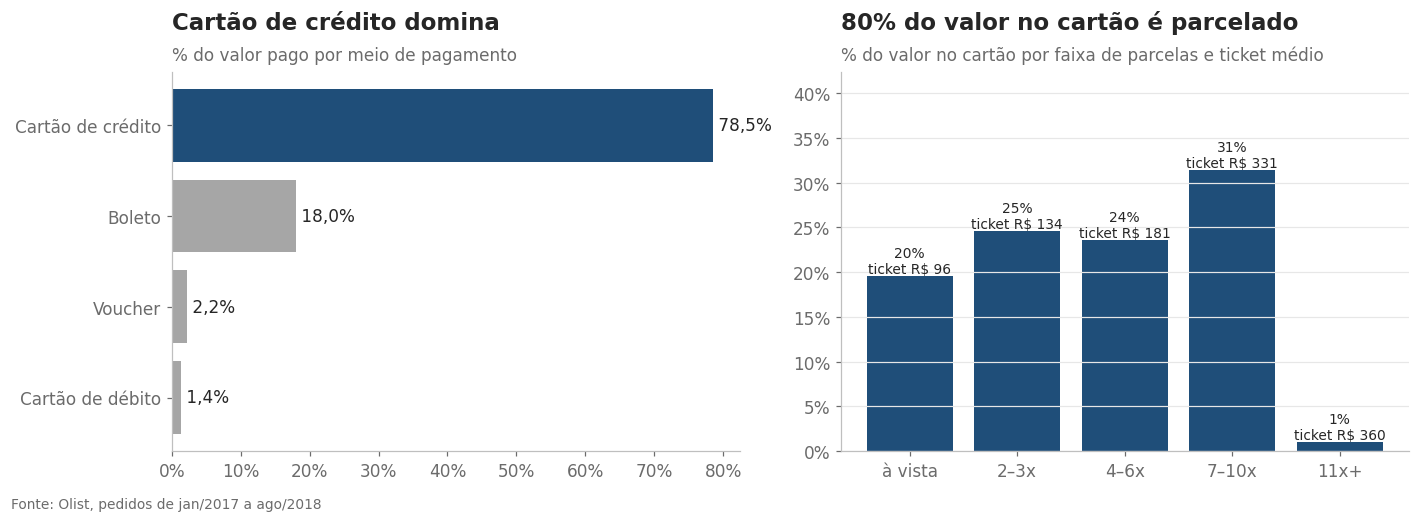

In [11]:
cartao = pag[pag.payment_type == "credit_card"]
faixa = pd.cut(cartao.payment_installments, [-1, 1, 3, 6, 10, 24], labels=["à vista", "2–3x", "4–6x", "7–10x", "11x+"])
parcelas = cartao.groupby(faixa, observed=True).agg(pagamentos=("order_id", "size"), ticket=("payment_value", "mean"), valor=("payment_value", "sum"))
parcelas["% dos pagamentos"] = parcelas.pagamentos / parcelas.pagamentos.sum()
parcelas["% do valor"] = parcelas.valor / parcelas.valor.sum()
parcelado = 1 - parcelas.loc["à vista", "% do valor"]
print(f"Valor pago no cartão em 2+ parcelas: {pct(parcelado)} | média de parcelas: {cartao.payment_installments.mean():.1f}")

cancelamento = (pedidos[pedidos.meio_pagamento != "not_defined"]
                .assign(cancelado=lambda d: d.order_status.isin(config.STATUS_INVALIDOS))
                .groupby("meio_pagamento").cancelado.mean().rename(index=nomes))
print("\nCancelamento/indisponibilidade por meio de pagamento:")
print(cancelamento.map(lambda v: pct(v, 2)).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axes[0]
tipos = por_tipo.loc[por_tipo["% do valor"] > 0.001, "% do valor"].iloc[::-1]
ax.barh(tipos.index, tipos, color=[CORES["neutro"]] * (len(tipos) - 1) + [CORES["principal"]])
for yi, v in enumerate(tipos):
    ax.text(v, yi, f" {pct(v)}", va="center")
ax.xaxis.set_major_formatter(viz.eixo_pct)
ax.grid(axis="y", visible=False)
viz.titulo(ax, "Cartão de crédito domina", "% do valor pago por meio de pagamento")
ax = axes[1]
barras = ax.bar(parcelas.index.astype(str), parcelas["% do valor"], color=CORES["principal"])
for barra, v, tk in zip(barras, parcelas["% do valor"], parcelas.ticket):
    ax.text(barra.get_x() + barra.get_width() / 2, v, f"{pct(v, 0)}\nticket {brl(tk)}", ha="center", va="bottom", fontsize=9)
ax.yaxis.set_major_formatter(viz.eixo_pct)
ax.set_ylim(0, parcelas["% do valor"].max() * 1.35)
viz.titulo(ax, f"{pct(parcelado, 0)} do valor no cartão é parcelado", "% do valor no cartão por faixa de parcelas e ticket médio")
fig.tight_layout()
viz.fonte(fig)
viz.salvar(fig, "04_pagamentos")